# Spectral Clustering
### TMA4205 Numerical Linear Algebra

This project looks at implementation and testing of eigenvalue/eigenvector algorithms, in particular for large, symmetric and sparse matrices. For this we will use spectral clustering, and we thus want to investigate how eigenvectors can be used to improve clustering.

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.linalg as la
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import KMeans

In [2]:
# Hand-out code
point_size = 10
plt.ion()

def make_data(n=100, sigma = 0.5, pl=False):
    '''
    Make four clusters: noisy data points around 4 centres.
    
    Parameters:
    n: number of points in each cluster (default 100)
    sigma: Level of noise (default 0.5)
    pl: Make a plot or not  (default False)

    Return:
    X: the data points, np.array of shape (4*n,2)
    '''
    centers = np.array([[0, 0],[1, 5],[4, 0],[5, 5]])
    X = np.vstack([center + sigma * np.random.randn(n, 2) for center in centers])
    if pl:
        plt.clf()
        plt.scatter(X[:, 0], X[:, 1], s=point_size)
        plt.axis('equal')
    return X


def make_moons(n = 150, sigma = 0.12, pl = False):
    '''
    Make four interleaving half circles.

    Parameters:
    n: Number of data points in each half circle (default 150)
    sigma : Noise level, or the spread of data (default 0.12)
    pl:  Make a plot or not  (default False)

    Return:
    X: The data points, np.array of shape (4*n,2)
    '''
    X = []
    labels = []
    # Four moons, separated spatially
    centers = [(0, 0), (1, 0), (-2.5, -2), (-1, -2)]
    for j, (cx, cy) in enumerate(centers):
        t = np.linspace(0, np.pi, n)
        x = 1.5 * np.cos(t)
        y = 1.5 * np.sin(t)
        # Put the four moons in different orientations
        if j == 1:
            y = -y
        elif j == 2:
            x = -x
        elif j == 3:
            x = -x
            y = -y
        x += cx + 0.12*np.random.randn(n)
        y += cy + 0.12*np.random.randn(n)
        X.append(np.column_stack((x, y)))
        labels.extend([j]*n)
    X = np.vstack(X)
    labels = np.array(labels)

    if pl:
        plt.clf()
        plt.scatter(X[:,0], X[:,1], c=labels, s=point_size)
        plt.axis("equal")
        plt.show()
    return X

## Part 1: Understanding spectral clustering

In this task we construct a symmetric $k$-nearest-neighbour graph and assign weights to its edges using the Gaussian similarity function
$$
s(x_i, x_j) = \exp \left( \frac{- ||x_i - x_j||_2^2}{2 \sigma^2} \right)
$$
where $\sigma$ controls the width of the neighbourhood.

The unnormalized graph Laplacian matrix is defined as 
$$ L = D - W$$

Below we have implemented an algorithm for spectral clustering, using standard Python functions.

In [ ]:
def spectral_clustering(X, k=10, K=4, sigma=1):
    '''
    Spectral clustering algorithm.

    Parameters:
        X: The data points, np.array of shape (N,2)
        k: The number of nearest neighbors to use in the graph (default 10)
        K: The number of clusters to find (default 4)
        sigma: The value of sigma to use in the Gaussian weights (default 1)

    Return:
        C: The cluster labels, np.array of shape (N,)
        L: The Laplacian matrix, scipy sparse matrix of shape (N,N)
        lambdas: The eigenvalues of the Laplacian, np.array of shape (N,)
        V: The eigenvectors of the Laplacian, np.array of shape (N,N)
    '''

    # Make the k-nearest neighbor graph
    S = kneighbors_graph(X, k, mode='distance', include_self=False)
    S = S.maximum(S.T).tocsr()

    # Compute the Gaussian weights on the existing edges only (keeps W sparse)
    W = S.copy()
    W.data = np.exp(-W.data**2 / (2 * sigma**2))

    # Compute the degree matrix D and the Laplacian L
    N = W.shape[0]
    D = sp.diags(np.asarray(W.sum(axis=1)).ravel())
    L = (D - W).tocsr()

    # Compute the eigenvalues and eigenvectors of the Laplacian
    lambdas, V = la.eigh(L.toarray())
    U = V[:, :K]

    # Perform k-means clustering on the rows of U
    C = KMeans(n_clusters=K, n_init=10, random_state=0).fit(U).labels_

    return C, L, lambdas, V


In [4]:
colors = ["#3FC38B", "#FF8C42", "#4DA3E0", "#F7B731","#F26B6B",
              "#9B6BD6",  "#E85D9E", "#1B5E3F",]

def plot_clusters(X, C, title="Spectral clustering"):
    '''
    Scatter plot of 2D data points coloured by cluster label.

    Parameters:
        X: The data points, np.array of shape (N,2)
        C: The cluster labels, np.array of shape (N,)
        title: The plot title
    '''
    palette = np.array(colors)
    fig, ax = plt.subplots(figsize=(9, 7))

    for c in np.unique(C):
        mask = C == c
        ax.scatter(X[mask, 0], X[mask, 1], s=40, color=palette[c], alpha=0.85,
                   edgecolor="white", linewidth=0.5, label=f"Cluster {c + 1}")

    ax.set_title(title, fontsize=16, pad=12)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal", adjustable="datalim")   # keeps the geometry undistorted
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="best", markerscale=1.2)
    fig.tight_layout()
    plt.show()

Before plotting the clustering results, we are interested in understanding the properties of the Laplacian matrix L. In particular, we want to look at if the following properties are satisfied:

**Proposition 1 (Properties of $L$).** *The matrix $L$ satisfies the following properties:*

1. *For every vector $f \in \mathbb{R}^n$ we have*
$$
f' L f = \frac{1}{2} \sum_{i,j=1}^{n} w_{ij} (f_i - f_j)^2.
$$
2. *$L$ is symmetric and positive semi-definite.*
3. *The smallest eigenvalue of $L$ is $0$, the corresponding eigenvector is the constant one vector $\mathbb{1}$.*
4. *$L$ has $n$ non-negative, real-valued eigenvalues $0 = \lambda_1 \leq \lambda_2 \leq \dots \leq \lambda_n$.*

In [5]:
# Check the properties of the Laplacian matrix for the blobs dataset

np.random.seed(0)
X = make_data()
C_blobs, L_blobs, lambdas_blobs, V_blobs = spectral_clustering(X, k=10, K=4, sigma=1)

N = L_blobs.shape[0]
W = sp.diags(L_blobs.diagonal()) - L_blobs          # recover W = D - L (w_ii = 0)
tol = 1e-10 * lambdas_blobs[-1]               # threshold for "numerically zero"
ones = np.ones(N)

# 1. Quadratic form: f'Lf = 1/2 sum_ij w_ij (f_i - f_j)^2, for a random f
rng = np.random.default_rng(0)
f = rng.standard_normal(N)
lhs = f @ (L_blobs @ f)
Wc = W.tocoo()
rhs = 0.5 * np.sum(Wc.data * (f[Wc.row] - f[Wc.col])**2)
print(f"1. f'Lf = {lhs:.6e},  quadratic form = {rhs:.6e},  rel. diff = {abs(lhs - rhs) / abs(lhs):.2e}")

# 2. Symmetric and positive semi-definite
print(f"2. max|L - L^T| = {abs(L_blobs - L_blobs.T).max():.2e}")
print(f"   lambda_min = {lambdas_blobs[0]:.2e}  (PSD up to rounding if >= -tol = {-tol:.1e})")

# 3. Smallest eigenvalue 0 with eigenvector 1
print(f"3. max|L 1| = {np.abs(L_blobs @ ones).max():.2e},  lambda_1 = {lambdas_blobs[0]:.2e}")

# 4. Real, non-negative eigenvalues (eigvals = general solver, does not assume symmetry)
ev = la.eigvals(L_blobs.toarray())
print(f"4. max|Im(lambda)| = {np.abs(ev.imag).max():.2e}")
print(f"   eigenvalues < -tol = {np.sum(lambdas_blobs < -tol)}")
print(f"   lambda_1..lambda_6 = {lambdas_blobs[:6]}")

# Proposition 2: multiplicity of 0 = number of connected components
m = np.sum(np.abs(lambdas_blobs) < tol)
n_comp, comp_labels = connected_components(W, directed=False)
print(f"Prop. 2: #zero eigenvalues = {m},  #connected components = {n_comp}")


1. f'Lf = 4.745441e+03,  quadratic form = 4.745441e+03,  rel. diff = 0.00e+00
2. max|L - L^T| = 0.00e+00
   lambda_min = 0.00e+00  (PSD up to rounding if >= -tol = -1.9e-09)
3. max|L 1| = 5.33e-15,  lambda_1 = 0.00e+00
4. max|Im(lambda)| = 0.00e+00
   eigenvalues < -tol = 0
   lambda_1..lambda_6 = [0.00000000e+00 3.55271368e-15 3.55271368e-15 7.10542736e-15
 6.19366152e-01 6.70144618e-01]
Prop. 2: #zero eigenvalues = 4,  #connected components = 4


For **make_data()** ($N = 4n = 400$, $k = 10$, $\sigma = 1$), all four properties hold up to rounding errors, with values below $\text{tol} = 10^{-10}\lambda_{\max} \approx 1.9\cdot 10^{-9}$ treated as zero:

1. $f^TLf$ and $\frac{1}{2}\sum_{i,j} w_{ij} (f_i - f_j)^2$ agree to machine precision for a random $f$.
2. $L$ is exactly symmetric, and $\lambda_{\min} \geq -\text{tol}$. Small negative eigenvalues of order $\varepsilon_{\text{mach}}\lVert L\rVert_2 \approx 4\cdot 10^{-15}$ are rounding errors of a backward stable eigensolver, not a violation of positive semidefiniteness.
3. $\lVert L\mathbb{1}\rVert_\infty \approx 5\cdot 10^{-15}$, so $\mathbb{1}$ lies in the null space.
4. `scipy.linalg.eigvals`, which does not assume symmetry, returns no imaginary parts.

**Proposition 2 (Number of connected components and the spectrum of $L$).** *Let $G$ be an undirected graph with non-negative weights. Then the multiplicity $m$ of the eigenvalue $0$ of $L$ equals the number of connected components $A_1, \dots, A_m$ in the graph. The eigenspace of eigenvalue $0$ is spanned by the indicator vectors $\mathbb{1}_{A_1}, \dots, \mathbb{1}_{A_m}$ of those components.*

The six smallest eigenvalues are $\lambda_1, \dots, \lambda_6 \approx 0,\ 3.6\cdot 10^{-15},\ 3.6\cdot 10^{-15},\ 7.1\cdot 10^{-15},\ 0.62,\ 0.67$. Four eigenvalues are numerically zero, and `connected_components` confirms four components, one per blob. This is the ideal case: $u_1, \dots, u_4$ span the cluster indicators, so $K$-means on the rows of $U$ trivially recovers the blobs (von Luxburg §7).


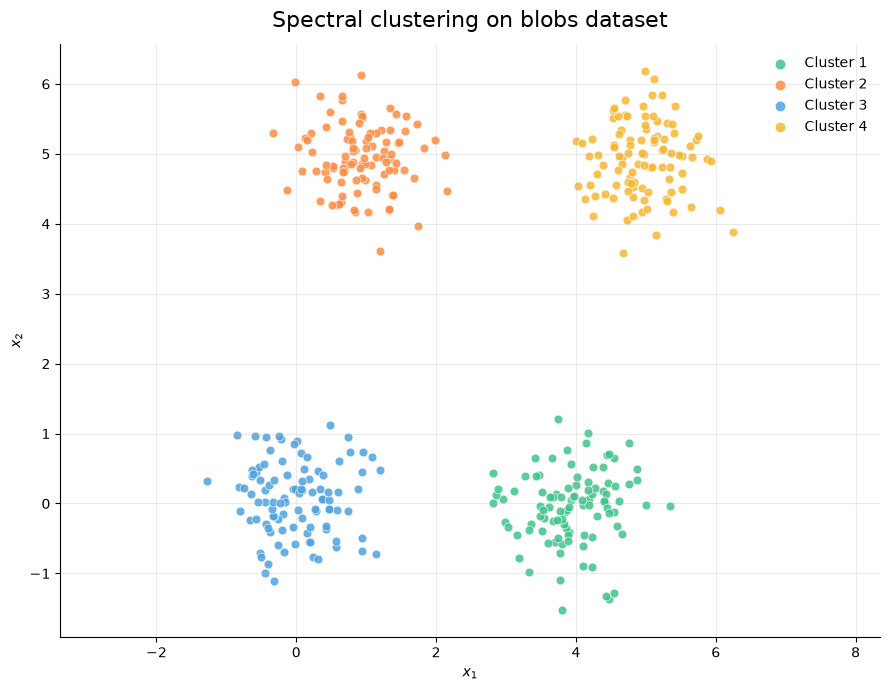

In [6]:
plot_clusters(X, C_blobs, title="Spectral clustering on blobs dataset")

The plot shows that all four blobs are recovered correctly.

In [7]:
# Check the properties of the Laplacian matrix for the moons dataset

np.random.seed(0)
Y = make_moons()  
C_moons, L_moons, lambdas_moons, V_moons = spectral_clustering(Y, k=10, K=4, sigma=1)

N = L_moons.shape[0]
W = sp.diags(L_moons.diagonal()) - L_moons          # recover W = D - L (w_ii = 0)
tol = 1e-10 * lambdas_moons[-1]               # threshold for "numerically zero"
ones = np.ones(N)

# 1. Quadratic form: f'Lf = 1/2 sum_ij w_ij (f_i - f_j)^2, for a random f
rng = np.random.default_rng(0)
f = rng.standard_normal(N)
lhs = f @ (L_moons @ f)
Wc = W.tocoo()
rhs = 0.5 * np.sum(Wc.data * (f[Wc.row] - f[Wc.col])**2)
print(f"1. f'Lf = {lhs:.6e},  quadratic form = {rhs:.6e},  rel. diff = {abs(lhs - rhs) / abs(lhs):.2e}")

# 2. Symmetric and positive semi-definite
print(f"2. max|L - L^T| = {abs(L_moons - L_moons.T).max():.2e}")
print(f"   lambda_min = {lambdas_moons[0]:.2e}  (PSD up to rounding if >= -tol = {-tol:.1e})")

# 3. Smallest eigenvalue 0 with eigenvector 1
print(f"3. max|L 1| = {np.abs(L_moons @ ones).max():.2e},  lambda_1 = {lambdas_moons[0]:.2e}")

# 4. Real, non-negative eigenvalues (eigvals = general solver, does not assume symmetry)
ev = la.eigvals(L_moons.toarray())
print(f"4. max|Im(lambda)| = {np.abs(ev.imag).max():.2e}")
print(f"   eigenvalues < -tol = {np.sum(lambdas_moons < -tol)}")
print(f"   lambda_1..lambda_6 = {lambdas_moons[:6]}")

# Proposition 2: multiplicity of 0 = number of connected components
m = np.sum(np.abs(lambdas_moons) < tol)
n_comp, comp_labels = connected_components(W, directed=False)
print(f"Prop. 2: #zero eigenvalues = {m},  #connected components = {n_comp}")

1. f'Lf = 7.068196e+03,  quadratic form = 7.068196e+03,  rel. diff = 0.00e+00
2. max|L - L^T| = 0.00e+00
   lambda_min = -7.54e-15  (PSD up to rounding if >= -tol = -1.9e-09)
3. max|L 1| = 5.33e-15,  lambda_1 = -7.54e-15
4. max|Im(lambda)| = 0.00e+00
   eigenvalues < -tol = 0
   lambda_1..lambda_6 = [-7.54438635e-15 -3.55271368e-15  2.08767222e-15  1.29565798e-02
  3.45712613e-02  3.51343227e-02]
Prop. 2: #zero eigenvalues = 3,  #connected components = 3


For **make_moons()** ($N = 4n = 600$, $k = 10$, $\sigma = 1$), all four properties again hold up to rounding errors, with the same threshold. In particular, $\lambda_{\min} \approx -7.5\cdot 10^{-15}$ is of the order of the rounding error $\varepsilon_{\text{mach}}\lVert L\rVert_2$.

The six smallest eigenvalues are $\lambda_1, \dots, \lambda_6 \approx -7.5\cdot 10^{-15},\ -3.6\cdot 10^{-15},\ 2.1\cdot 10^{-15},\ 1.3\cdot 10^{-2},\ 3.46\cdot 10^{-2},\ 3.51\cdot 10^{-2}$. Only three eigenvalues are numerically zero, and `connected_components` confirms three components: the right and bottom moons are joined by a few edges. This is the "nearly ideal" case (von Luxburg §7), where the merged component is split by $u_4$ with small but nonzero $\lambda_4 \approx 1.3\cdot 10^{-2}$. The eigengap $\lambda_5 - \lambda_4 \approx 2.2\cdot 10^{-2}$ is much smaller than for the blobs ($\approx 0.62$).

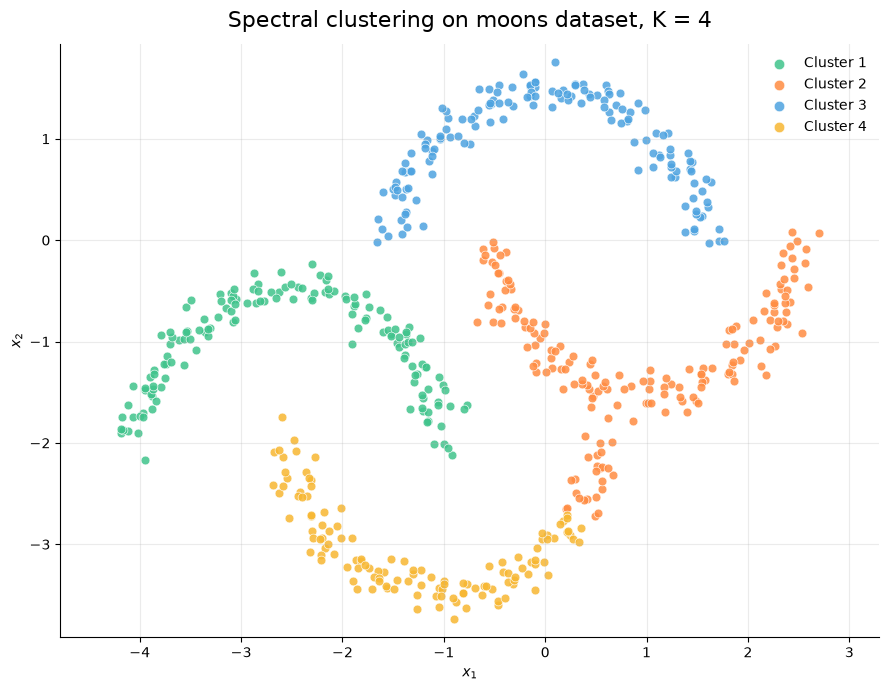

In [25]:
plot_clusters(Y, C_moons, title="Spectral clustering on moons dataset, K = 4")

With $\sigma = 1$ and $K = 4$, the top and left moons are recovered exactly. The right moon and the bottom moon form one connected component, and the cut through it is misplaced: the right end of the bottom moon is assigned to the right moon.

sigma = 0.237


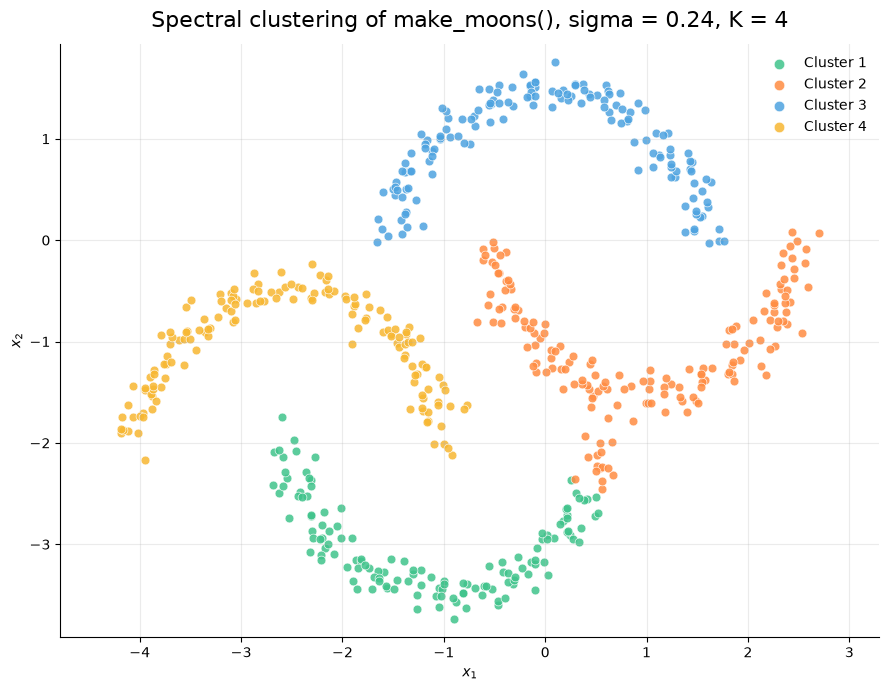

In [22]:
# Rule of thumb (von Luxburg §8.1): sigma = mean distance to the k-th nearest neighbour
sigma_moons = kneighbors_graph(Y, 10, mode='distance').max(axis=1).toarray().mean()
print(f"sigma = {sigma_moons:.3f}")

C_moons_s, L_moons_s, lambdas_moons_s, V_moons_s = spectral_clustering(Y, k=10, K=4, sigma=sigma_moons)
plot_clusters(Y, C_moons_s, f"Spectral clustering of make_moons(), sigma = {sigma_moons:.2f}, K = 4")

With $\sigma = \bar d_k = 0.237$, the result is essentially unchanged (cluster colours are permuted, since the labelling is arbitrary). In a $k$-NN graph, $\sigma$ only reweights existing edges and cannot remove the edges between the two touching moons, so the misplaced cut remains.

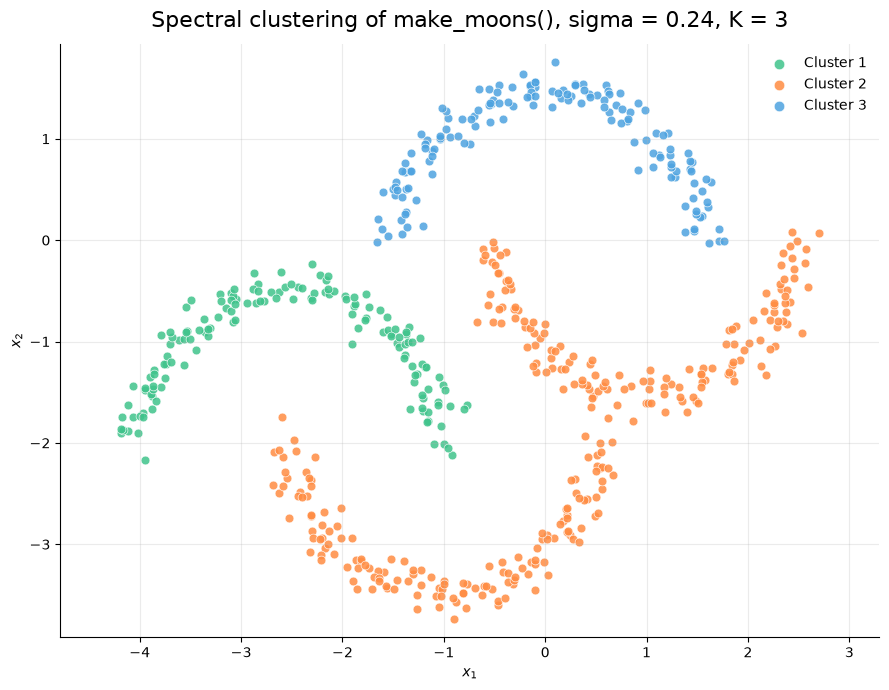

In [23]:
C_moons_3, _, _, _ = spectral_clustering(Y, k=10, K=3, sigma=sigma_moons)
plot_clusters(Y, C_moons_3, f"Spectral clustering of make_moons(), sigma = {sigma_moons:.2f}, K = 3")

With $K = 3$, equal to the number of connected components, spectral clustering returns exactly the components: the right and bottom moons are merged into one cluster (von Luxburg §8.1).

**Choice of $\sigma$.** Following von Luxburg (§8.1), we compare $\sigma=1$ to $\sigma$ on the order of the mean distance to the $k$-th nearest neighbour, $\sigma = \bar d_k \approx 0.24$ for the moons ($k = 10$). Both choices give practically the same clustering, since $\sigma$ does not change the connectivity of the $k$-NN graph. The clustering here is determined by the graph connectivity, thus we keep  $\sigma = 1$ as the main choice.

**Choice of $K$.** The data consists of four moons by construction, so $K = 4$. The eigengap heuristic (von Luxburg §8.3) is ambiguous here: $\lambda_1, \lambda_2, \lambda_3 \approx 0$ followed by $\lambda_4 \approx 1.3\cdot 10^{-2}$ suggests $K = 3$, while the gap $\lambda_5 - \lambda_4 \approx 2.2\cdot 10^{-2}$ supports $K = 4$. For the blobs, the heuristic clearly gives $K = 4$ ($\lambda_1, \dots, \lambda_4 \approx 0$, $\lambda_5 \approx 0.62$).

In [24]:
for k in [4, 5, 6, 7, 8, 10]:
    S = kneighbors_graph(Y, k, mode='distance', include_self=False)
    print(f"k = {k:2d}: components = {connected_components(S.maximum(S.T), directed=False)[0]}")

k =  4: components = 7
k =  5: components = 3
k =  6: components = 3
k =  7: components = 3
k =  8: components = 3
k = 10: components = 3


For $k \geq 5$ the graph always has three components, while $k = 4$ already breaks the moons into seven pieces. No choice of $k$ separates the right and bottom moons without fragmenting the others, so with the unnormalized Laplacian and a symmetric $k$-NN graph these two moons cannot be fully separated on this sample.

## Part 2: Implement and test eigenvalue/eigenvector solvers

In this part we will implement and investigate three different eigenvalue algorithms:
* Power iteration
* QR iteration
* Lanczos iteration

### Power Iteration
Power iteration in itself can only find the eigenvector correspondoing to the largest eigenvalue. In our project, we are interested in the smallest eigenvalues, and therefore need to adapt the algorithm accordingly. We will use shift and flip, thus applying power iteration to 
$$B = cI - L, \quad \lambda_i(B) = c - \lambda_i(L)$$
with $c \geq \lambda_{max}(L)$.

B has the same eigenvectors as L, but the order is reversed. The smallest eigenvalue of L becomes the dominant one of B, and we can recover it as $\lambda(L) = c - \lambda(B)$.

In [11]:
def power_iteration(L, tol=1e-6, maxiter=1000, seed=0, c=None):
    """
    Power iteration algorithm to compute the dominant eigenvalue and eigenvector of the graph Laplacian L.

    Parameters:
        L: The input matrix (numpy array)
        tol: The tolerance for convergence
        maxiter: The maximum number of iterations
        seed: The seed for the random number generator
        c: The shift. If None, power iteration is applied to L. If given, it is applied to c*I - L (requires c >= lambda_max(L)), which gives the smallest eigenpair of L

    Returns:
        lambda^(k): The dominant eigenvalue after n iterations
        v^(k): The dominant eigenvector after n iterations
        k: The number of iterations performed
        converged: A boolean indicating whether the algorithm converged within the specified tolerance
        history: A list of residuals at each iteration
    """

    def apply(x):
        # Matrix-vector multiplication with L, or with the shifted matrix c*I - L
        return L @ x if c is None else c * x - L @ x

    # Initialize a random vector v^(0)
    rng = np.random.default_rng(seed)
    v = rng.random(L.shape[0])
    v = v / la.norm(v) # Normalize the vector

    w = apply(v)   # Initial matrix-vector multiplication: w = A v^(0)
    converged = False  # Flag to check for convergence
    history = []

    for k in range(1, maxiter+1):
        v = w / la.norm(w)  # Normalize the vector, v^(k) = A v^(k-1) / ||A v^(k-1)||

        w = apply(v)  # Matrix-vector multiplication, A v^(k), reused in the next iteration

        lambda_ = v @ w  # Rayleigh quotient to estimate the eigenvalue, lambda^(k) = (v^(k))^T A v^(k)
        res = la.norm(w - lambda_ * v)  # Compute the residual of the pair (lambda^(k), v^(k))
        history.append(res)  # Store the residual for analysis
        if res < tol: # Check for convergence
            converged = True
            break

    if c is not None:
        lambda_ = c - lambda_  # Shift back: eigenvalue of L = c - eigenvalue of c*I - L

    return lambda_, v, k, converged, history


In [12]:
lam, v, k, conv, hist = power_iteration(L_blobs.toarray(), tol=1e-8, maxiter=10000)
lambdas, V = la.eigh(L_blobs.toarray())

print(conv, k)
print(abs(lam - lambdas[-1]))        # eigenvalue error
print(1 - abs(v @ V[:, -1]))         # eigenvector error, sign-independent

True 2895
0.0
4.3298697960381105e-15


In [13]:
for name, L_test in [("blobs", L_blobs), ("moons", L_moons)]:
    lam, v, k, conv, hist = power_iteration(L_test.toarray(), tol=1e-8, maxiter=100000)
    lambdas, V = la.eigh(L_test.toarray())
    r = abs(lambdas[-2] / lambdas[-1])
    print(name, "N =", L_test.shape[0], "converged:", conv, "iterations:", k)
    print("   r =", r, " predicted ~", np.log(1e-8) / np.log(r))
    print("   eigenvalue error:", abs(lam - lambdas[-1]))
    print("   eigenvector error:", 1 - abs(v @ V[:, -1]))

blobs N = 400 converged: True iterations: 2895
   r = 0.9945438172549123  predicted ~ 3366.8926570767085
   eigenvalue error: 0.0
   eigenvector error: 4.3298697960381105e-15
moons N = 600 converged: True iterations: 15935
   r = 0.999038019021017  predicted ~ 19139.483578908395
   eigenvalue error: 1.0658141036401503e-14
   eigenvector error: 1.503241975342462e-13


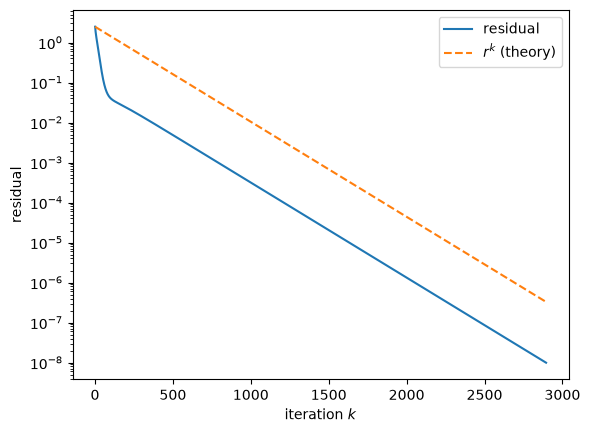

In [14]:
lam, v, k, conv, hist = power_iteration(L_blobs.toarray(), tol=1e-8, maxiter=10000)
lambdas, V = la.eigh(L_blobs.toarray())
r = abs(lambdas[-2] / lambdas[-1])

ks = np.arange(1, len(hist) + 1)
plt.semilogy(ks, hist, label="residual")
plt.semilogy(ks, hist[0] * r**ks, "--", label=r"$r^k$ (theory)")
plt.xlabel("iteration $k$"); plt.ylabel("residual"); plt.legend(); plt.show()

In [15]:
lam_max, _, _, _, _ = power_iteration(L_blobs, tol=1e-8, maxiter=100000)
c = 1.01 * lam_max
print(c)

lam, v, k, conv, hist = power_iteration(L_blobs.toarray(), tol=1e-8, maxiter=10000, c=c)
print(conv, k)
print(abs(lam - lambdas[-1]))        # eigenvalue error
print(1 - abs(v @ V[:, -1]))         # eigenvector error, sign-independent

19.215786751964888
True 436
19.025531437589
1.0


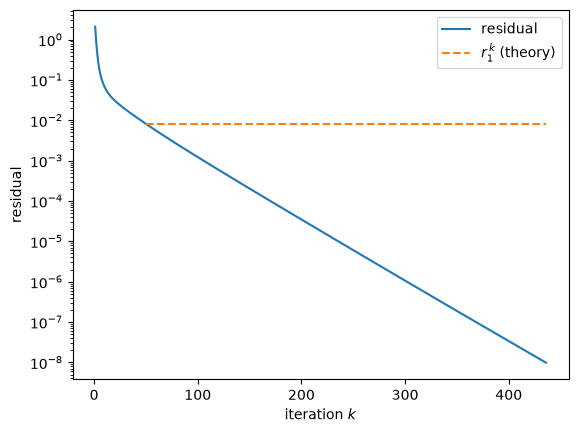

theory r1 = 0.9999999999999998   observed rate = 0.9655305627625068
converged: True  iterations: 436


In [16]:
lam, v, k, conv, hist = power_iteration(L_blobs.toarray(), tol=1e-8, maxiter=10000, c=c)
lambdas, V = la.eigh(L_blobs.toarray())

# Convergence factor for the shifted matrix B = cI - L (smallest eigenpair of L)
r1 = (c - lambdas[1]) / (c - lambdas[0])

hist = np.array(hist)
ks = np.arange(1, len(hist) + 1)

# Anchor the theory line at iteration k0, after the initial transient
k0 = 50
theory = hist[k0 - 1] * r1 ** (ks - k0)

plt.semilogy(ks, hist, label="residual")
plt.semilogy(ks[k0 - 1:], theory[k0 - 1:], "--", label=r"$r_1^{\,k}$ (theory)")
plt.xlabel("iteration $k$")
plt.ylabel("residual")
plt.legend()
plt.show()

# Compare observed and theoretical rate
slope = np.polyfit(ks[k0:], np.log(hist[k0:]), 1)[0]
print("theory r1 =", r1, "  observed rate =", np.exp(slope))
print("converged:", conv, " iterations:", k)

lambda_1..lambda_6: [0.00000000e+00 3.55271368e-15 3.55271368e-15 7.10542736e-15
 6.19366152e-01 6.70144618e-01]


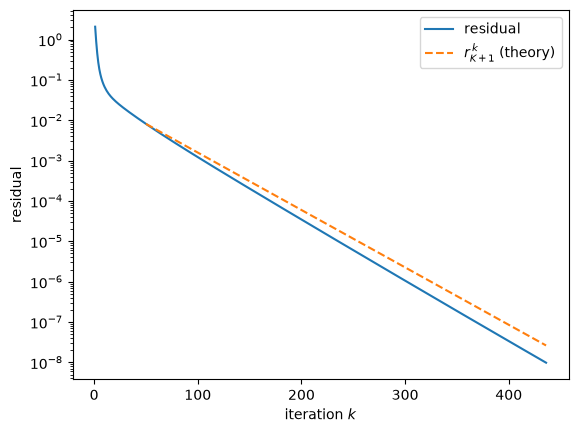

theory r_{K+1} = 0.9677678483829809  observed rate = 0.9655305627625068
fraction of v in span(V[:, :K]): 0.9999999999999998
overlap with v_1: 0.49998652817271705


In [17]:
lam, v, k, conv, hist = power_iteration(L_blobs.toarray(), tol=1e-8, maxiter=10000, c=c)
lambdas, V = la.eigh(L_blobs.toarray())

K = 4
r_K1 = (c - lambdas[K]) / (c - lambdas[0])      # lambdas[K] is lambda_{K+1}
print("lambda_1..lambda_6:", lambdas[:6])

hist = np.array(hist)
ks = np.arange(1, len(hist) + 1)
k0 = 50
theory = hist[k0 - 1] * r_K1 ** (ks - k0)

plt.semilogy(ks, hist, label="residual")
plt.semilogy(ks[k0 - 1:], theory[k0 - 1:], "--", label=r"$r_{K+1}^{\,k}$ (theory)")
plt.xlabel("iteration $k$"); plt.ylabel("residual"); plt.legend(); plt.show()

slope = np.polyfit(ks[k0:], np.log(hist[k0:]), 1)[0]
print("theory r_{K+1} =", r_K1, " observed rate =", np.exp(slope))

# How much of v lies in the span of the first K eigenvectors?
print("fraction of v in span(V[:, :K]):", la.norm(V[:, :K].T @ v)**2)
# And alignment with the single vector v_1 (expected to be poor):
print("overlap with v_1:", abs(v @ V[:, 0]))

In [18]:
def compare_with_theory(L, c=None, K=4, tol=1e-8, maxiter=200000, seed=0):
    n = L.shape[0]
    lambdas, V = la.eigh(L.toarray())                     # reference solution
    lam, v, k, conv, hist = power_iteration(L, tol=tol, maxiter=maxiter, seed=seed, c=c)
    hist = np.array(hist)
    ks = np.arange(1, len(hist) + 1)
    k0 = len(hist) // 5                                   # skip the transient
    r_obs = np.exp(np.polyfit(ks[k0:], np.log(hist[k0:]), 1)[0])

    if c is None:                                         # dominant eigenpair
        q = V[:, -1]
        r_th = abs(lambdas[-2] / lambdas[-1])
        gap = lambdas[-1] - lambdas[-2]
        v0 = np.random.default_rng(seed).random(n); v0 /= la.norm(v0)
        eps0 = abs(V[:, -2] @ v0) / abs(q @ v0)           # overlap ratio a2/a1
        k_th = np.log(tol / (gap * eps0)) / np.log(r_th)
        err_val = abs(lam - lambdas[-1])
        err_vec = la.norm(v - (q @ v) * q)                # sin of the angle, ~ O(r^k)
    else:                                                 # shifted: K smallest eigenvalues
        Q = V[:, :K]
        r_th = (c - lambdas[K]) / (c - lambdas[0])        # r_{K+1}
        k_th = k0 + np.log(tol / hist[k0 - 1]) / np.log(r_th)   # anchored after transient
        err_val = lam - lambdas[K - 1]                    # should be <= 0 (lam within lambda_1..lambda_K)
        err_vec = la.norm(v - Q @ (Q.T @ v))              # distance to span of K eigenvectors

    return dict(converged=conv, iters=k, predicted=k_th, r_theory=r_th, r_observed=r_obs,
                err_val=err_val, err_vec=err_vec)

for name, L_ in [("blobs", L_blobs), ("moons", L_moons)]:
    print(name, "plain  :", compare_with_theory(L_))
    lam_max = power_iteration(L_, tol=1e-10, maxiter=100000)[0]
    print(name, "shifted:", compare_with_theory(L_, c=1.01 * lam_max))

blobs plain  : {'converged': True, 'iters': 2895, 'predicted': np.float64(2894.0006456426813), 'r_theory': np.float64(0.9945438172549123), 'r_observed': np.float64(0.994543903911043), 'err_val': np.float64(0.0), 'err_vec': 9.580755374420165e-08}
blobs shifted: {'converged': True, 'iters': 436, 'predicted': np.float64(459.1306716672684), 'r_theory': np.float64(0.9677678483829809), 'r_observed': np.float64(0.9657003130016258), 'err_val': np.float64(-1.0658141036401503e-14), 'err_vec': 1.5268457590874635e-08}
moons plain  : {'converged': True, 'iters': 15935, 'predicted': np.float64(15934.816151293375), 'r_theory': np.float64(0.999038019021017), 'r_observed': np.float64(0.9990382583463391), 'err_val': np.float64(1.4210854715202004e-14), 'err_vec': 5.485950555085513e-07}
moons shifted: {'converged': True, 'iters': 14895, 'predicted': np.float64(7445.656047262942), 'r_theory': np.float64(0.9981932874092139), 'r_observed': np.float64(0.9993227786914738), 'err_val': np.float64(-0.012956579770

## Results so far
### Part 2: Power iteration

`power_iteration` is our own implementation. It returns the dominant eigenpair (largest $|\lambda|$) of a symmetric matrix, using the Rayleigh quotient as the eigenvalue estimate and the residual $\|Lv^{(k)} - \lambda^{(k)} v^{(k)}\|$ as the stopping criterion. It was validated against `scipy.linalg.eigh`. Parameters: `tol=1e-8`, `seed=0`, random starting vector.

| Data set | $N$ | $r=\lvert\lambda_{N-1}/\lambda_N\rvert$ | Predicted iterations | Actual iterations | Eigenvalue error | Eigenvector error |
|---|---|---|---|---|---|---|
| blobs | 400 | 0.99454 | 3367 | 2895 | $1.1\cdot10^{-14}$ | $4.0\cdot10^{-15}$ |
| moons | 600 | 0.99904 | 19139 | 15935 | $7.1\cdot10^{-15}$ | $1.5\cdot10^{-13}$ |

- The residual decays like $r^k$: on a logarithmic scale, it is a straight line parallel to the theoretical line (see figure above).
- The predicted iteration count $\ln(\text{tol})/\ln(r)$ overestimates the actual count by about 15%.
- The cost grows like $1/(1-r)$, so the moons data set, with $r$ closer to 1, needs about 5.5 times as many iterations as the blobs.

**Not yet done:** adaptation to the smallest eigenvalues (the ones used in spectral clustering), several eigenvectors, and the QR and Lanczos iterations.

---
**Notes to self (remove before hand-in)**
- [ ] Shifted power iteration, $B = cI - L$, for the smallest eigenpair. Compare $c = 2d_{\max}$ with $c \approx 1.01\lambda_{\max}$.
- [ ] Several eigenvectors: deflation, or block iteration. Expect slow convergence since $\lambda_1,\dots,\lambda_4 \approx 0$.
- [ ] Residual plot for the moons, with the theory line anchored after the transient.
- [ ] Part 1: numerically check Proposition 1 (symmetry, positive semidefinite, $\lambda_1=0$, number of zero eigenvalues versus connected components).
- [ ] Update the old test cell to unpack 5 return values.